In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm.auto import tqdm
import itertools

In [3]:
import mctpy as mct

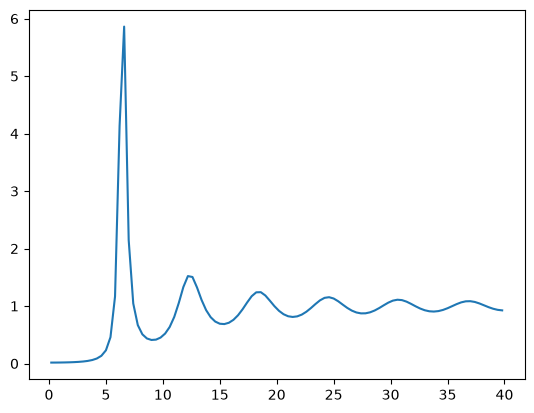

In [4]:
Sq = mct.structurefactors.hssFMT2d(0.7)
qgrid = np.linspace(0.2,39.8,100)
sq,cq = Sq.Sq(qgrid)
plt.plot(qgrid,sq)
plt.show()

In [5]:
model = mct.simple_liquid_model_2d(Sq,qgrid)

In [6]:
nep = mct.nonergodicity_parameter (model = model)
nep.solve()

In [7]:
cs = Sq # tagged particle of same type as host
model_s = mct.tagged_particle_model_2d (model, Sq=cs, D0s=1)
nep_s = mct.nonergodicity_parameter (model = model_s)
nep_s.solve()

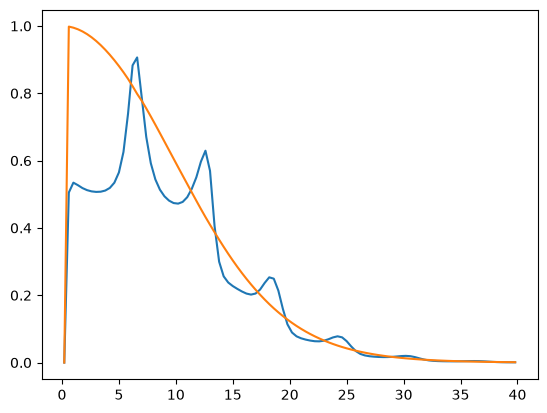

In [8]:
plt.plot(nep.model.q, nep.f)
plt.plot(nep_s.model.q, nep_s.f)
plt.show()

In [9]:
qgrid=np.linspace(0.2,39.8,100)
Sq = mct.structurefactors.hssFMT2d(0.685)
model = mct.simple_liquid_model_2d(Sq,qgrid)
phi = mct.correlator (model = model, store=True)

In [10]:
phi.solve_all(stop_on_zero=True, progress_bar=tqdm)

  0%|          | 0/60 [00:00<?, ?it/s]

False

In [11]:
qvals = [3.4,7.4,12.2]
qis = np.array([np.nonzero(np.isclose(qgrid,qval)) for qval in qvals],dtype=int).reshape(-1)

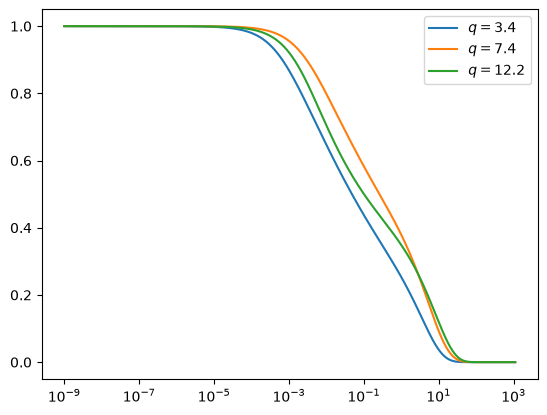

In [12]:
#qis=range(qgrid.shape[0])
for qi in qis:
    plt.plot(phi.t[phi.t>0], phi.phi[phi.t>0,qi], label=r'$q = {:.1f}$'.format(qgrid[qi]))
plt.xscale('log')
plt.legend()
plt.show()

In [13]:
cs = Sq
model_s = mct.tagged_particle_model_2d (model, Sq=cs, D0s=1)
phi_s = mct.correlator (model = model_s, store = True)
correlators = mct.CorrelatorStack([phi,phi_s])

In [14]:
correlators.solve_all(progress_bar=tqdm)

  0%|          | 0/60 [00:00<?, ?it/s]

True

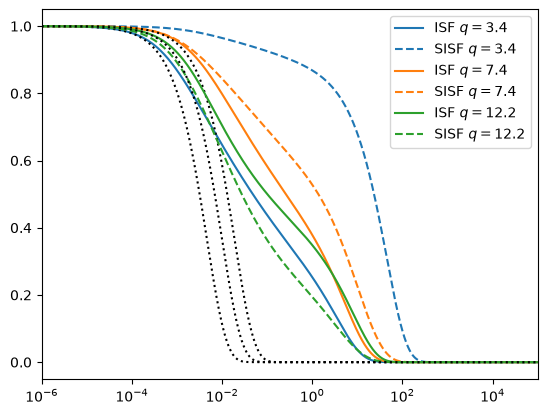

In [15]:
colors = itertools.cycle(plt.rcParams['axes.prop_cycle'].by_key()['color'])
for qi in qis:
    c = next(colors)
    plt.plot(phi.t,phi.phi[:,qi],color=c,label=r'ISF $q = {:.1f}$'.format(qgrid[qi]))
    plt.plot(phi_s.t, phi_s.phi[:,qi], label=r'SISF $q = {:.1f}$'.format(qgrid[qi]),linestyle='dashed',color=c)
    plt.plot(phi.t,np.exp(-qgrid[qi]**2/Sq.Sq(qgrid)[0][qi] * phi.t), color='black', linestyle='dotted')
plt.xscale('log')
plt.xlim(1e-6,1e5)
plt.legend()
plt.show()